# Connected Scatter Plot

**Family:** Correlation &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Correlation:* Show the relationship between two or more variables.

## Design purpose

A scatter plot whose points are joined in time order. It shows how the relationship between two variables changes over time, including loops, reversals and turning points.

## When to use

- Show how two variables evolved together over time (e.g. unemployment vs. inflation)
- Show cycles and path dependency that two separate line charts would hide

## Avoid when

- The audience is unfamiliar with the form (it needs annotation to be read)
- There are many time points or a path that crosses itself a lot
- There are several series (paths tangle)

## Alternatives

- Two aligned line charts (small multiples)
- Indexed line chart

## Design tips

- Label the start, the end and key turning points with years
- Use arrows or a light-to-dark gradient to show direction

## Example

Annual unemployment vs. inflation rate for a fictional economy, 2004–2023 (Phillips-curve style).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(4)
years = np.arange(2004, 2024)
t = np.linspace(0, 3 * np.pi, len(years))
unemployment = 6 + 2.2 * np.sin(t) + rng.normal(0, 0.3, len(years))
inflation = 2.5 + 1.8 * np.cos(t) + rng.normal(0, 0.3, len(years))
df = pd.DataFrame({"year": years, "unemployment": unemployment, "inflation": inflation})
df.head()

,year,unemployment,inflation
0,2004,5.804463,4.103114
1,2005,6.994669,3.881448
2,2006,8.340883,3.598563
3,2007,8.390230,2.615625
4,2008,7.522282,2.221720


### Plot

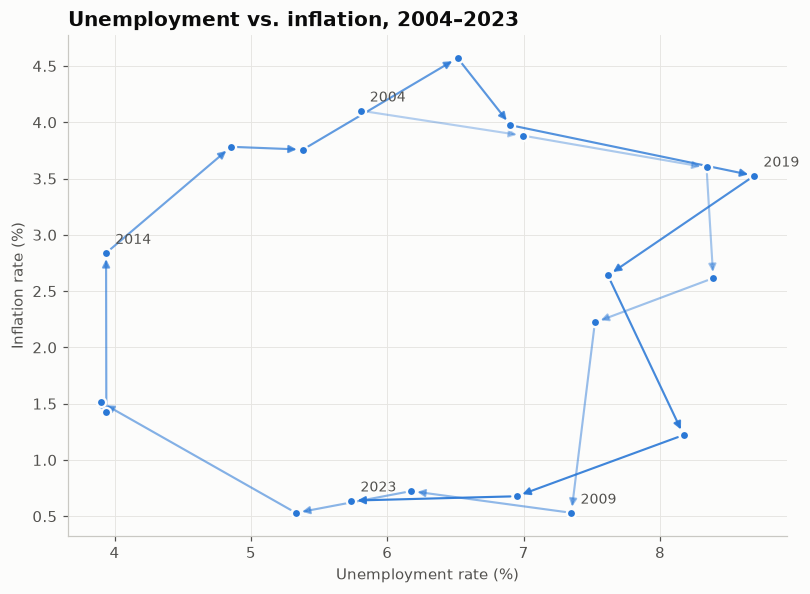

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
x, y = df["unemployment"].values, df["inflation"].values
for i in range(len(df) - 1):
    ax.annotate("", xy=(x[i + 1], y[i + 1]), xytext=(x[i], y[i]),
                arrowprops=dict(arrowstyle="-|>", color=PALETTE[0], lw=1.4,
                                alpha=0.35 + 0.65 * i / len(df), shrinkA=4, shrinkB=4))
ax.scatter(x, y, s=36, color=PALETTE[0], edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
for i in [0, 5, 10, 15, len(df) - 1]:
    ax.annotate(str(df["year"].iloc[i]), (x[i], y[i]), xytext=(6, 6),
                textcoords="offset points", fontsize=9, color="#52514e")
ax.set_xlabel("Unemployment rate (%)")
ax.set_ylabel("Inflation rate (%)")
ax.set_title("Unemployment vs. inflation, 2004–2023")
fig.tight_layout()
plt.show()

## How to read it

Follow the arrows from 2004 (faint) to 2023 (solid). Each step is one year. The looping path shows the economy cycling between high-inflation and high-unemployment phases.

---
Standalone script: [`connected_scatter.py`](connected_scatter.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)